In [7]:
import duckdb as db
import polars as pl
import os, glob, sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from power_speed_fit import fit_power_law, plot_fit, _xy,poly

sys.path.insert(0, os.path.join("..", "..", "src"))
from cfg import DROP, STD_COLS, COUNT_COLS, SHORT, HERE, DATASET, PROCESSED, DB_PATH, load_extensions

In [8]:
plt.rcParams['axes.grid'] = True          # Enable the grid by default
plt.rcParams['grid.color'] = '#d3d3d3'  # soft light gray

In [9]:
conn = db.connect(database=DB_PATH)
noon_reports = conn.execute("SELECT * FROM cleaned_noon_reports").pl()
metrics_reg = conn.execute("SELECT * FROM metrics_registration").pl()
metrics_wide = conn.execute("SELECT * FROM metrics_wide").pl()
trips = conn.execute("SELECT * FROM trips").pl()
conn.close()

c:\AID Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


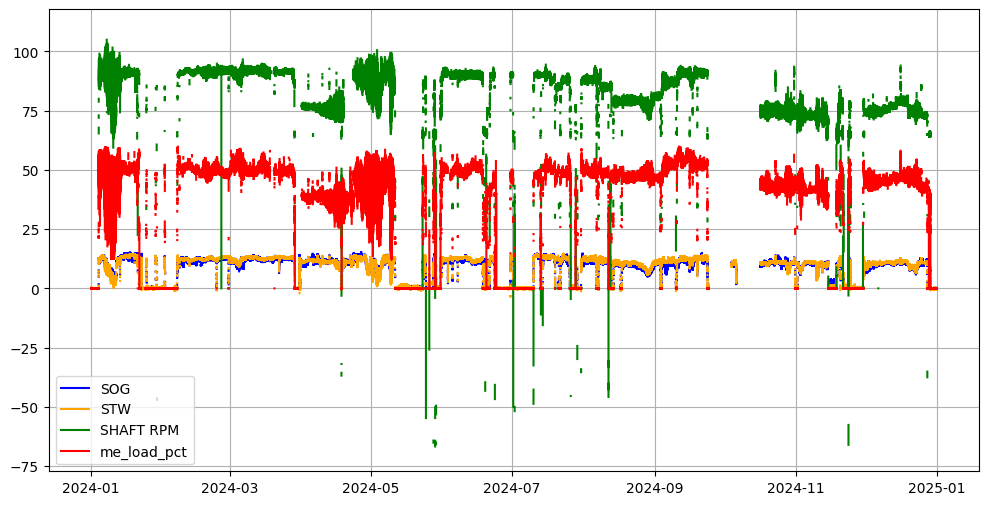

In [9]:
plt.figure(figsize=(12, 6))
plt.grid(True)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["sog_kn"].to_numpy(), color = "blue", label = "SOG")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["stw_kn"].to_numpy(), color = "orange", label = "STW")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["me_rpm"].to_numpy(), color = "green", label = "SHAFT RPM")
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["me_load_pct"].to_numpy(), color = "red", label = "me_load_pct")
plt.legend()
plt.show()

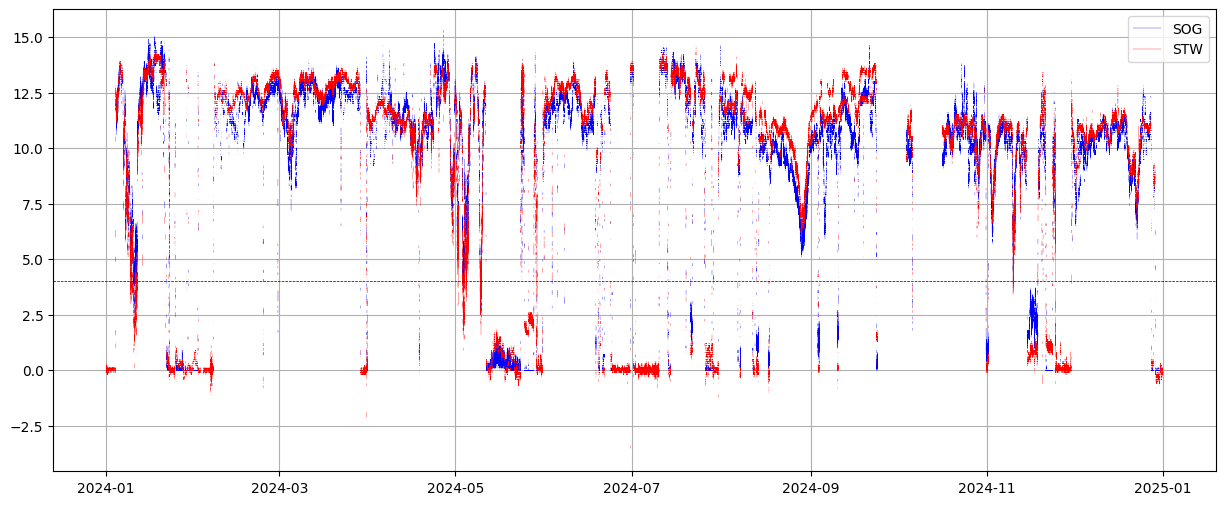

In [ ]:
plt.figure(figsize=(15, 6))
plt.grid(True)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["sog_kn"].to_numpy(), color = "blue", label = "SOG", lw=0.25)
plt.plot(metrics_wide["timestamp"].to_numpy(), metrics_wide["stw_kn"].to_numpy(), color = "red", label = "STW", lw=0.25)
plt.axhline(4, color = "black", ls = "--", lw = 0.5, )
ax.text(x=metrics_wide["timestamp"][0],y=4,s="4kn",color='white',fontweight='bold',va='center',ha='center',bbox=dict(facecolor='red', edgecolor='none', boxstyle='round,pad=0.3'))
plt.axhline(4, color = "black", ls = "--", lw = 0.5, )
ax.text(x=metrics_wide["timestamp"][0],y=4,s="4kn",color='white',fontweight='bold',va='center',ha='center',bbox=dict(facecolor='red', edgecolor='none', boxstyle='round,pad=0.3'))
plt.legend(loc= "upper right")
plt.show()

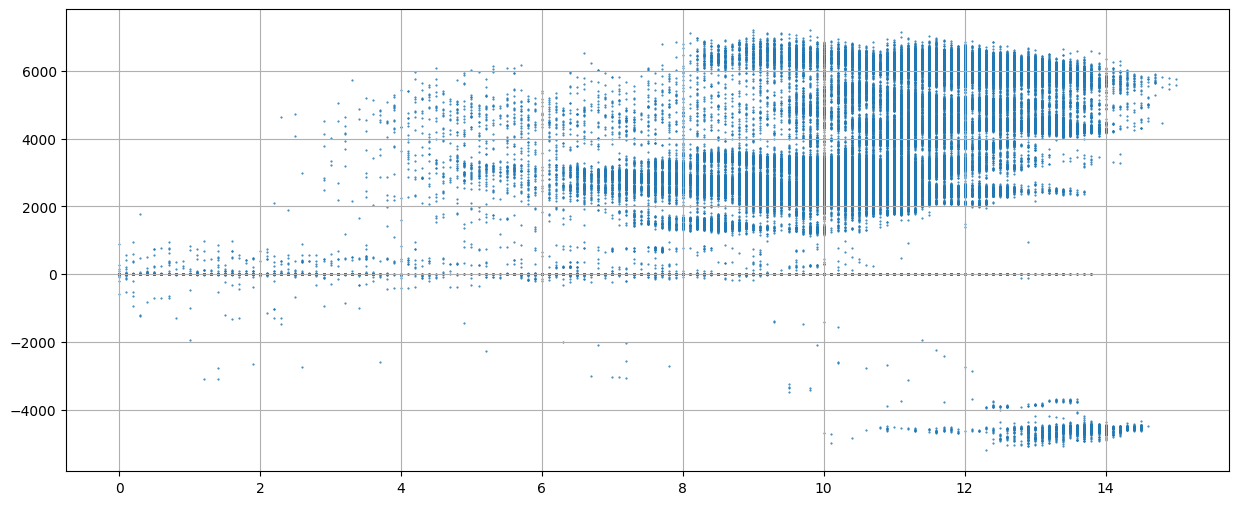

In [9]:
plt.figure(figsize=(15, 6))
plt.grid(True)
plt.scatter(metrics_wide["sog_kn"].to_numpy(),metrics_wide["shaft_kw"].to_numpy(), s= 0.25 )
plt.show()

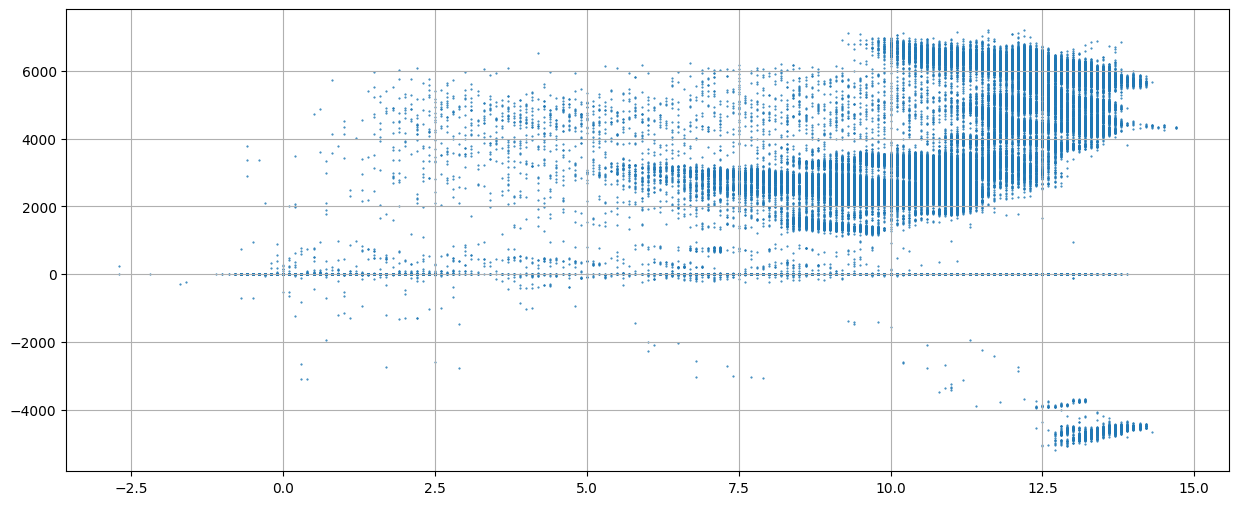

In [10]:
plt.figure(figsize=(15, 6))
plt.grid(True)
plt.scatter( metrics_wide["stw_kn"].to_numpy(),metrics_wide["shaft_kw"].to_numpy(),s = 0.25 )
plt.show()

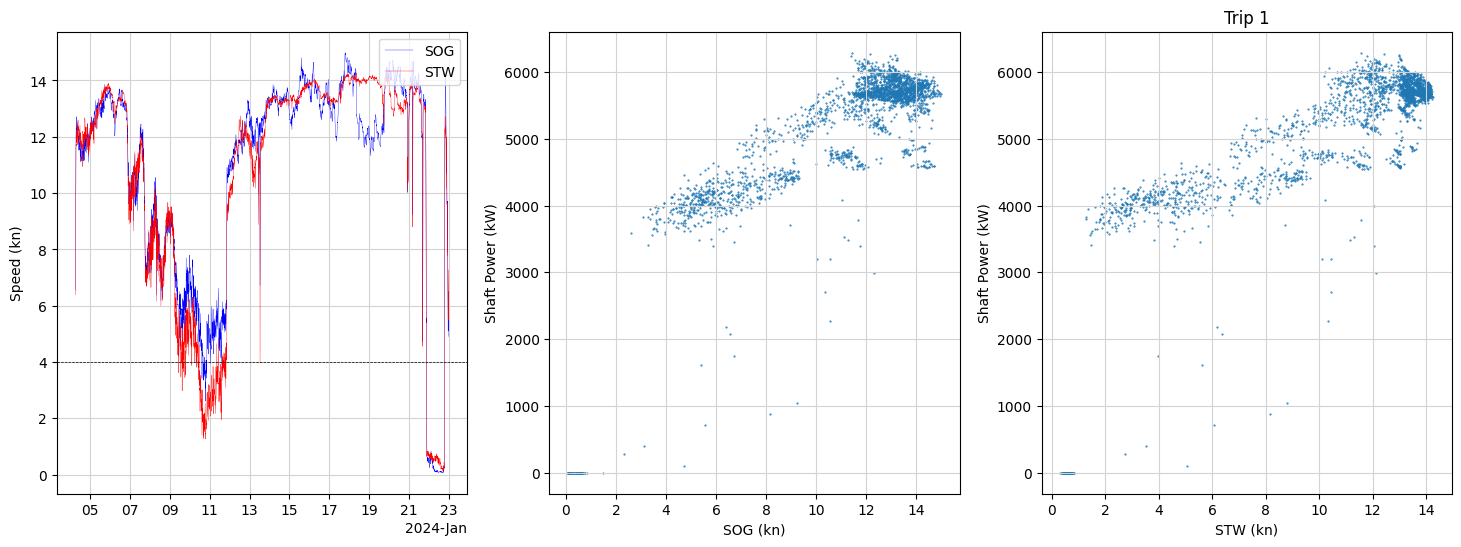

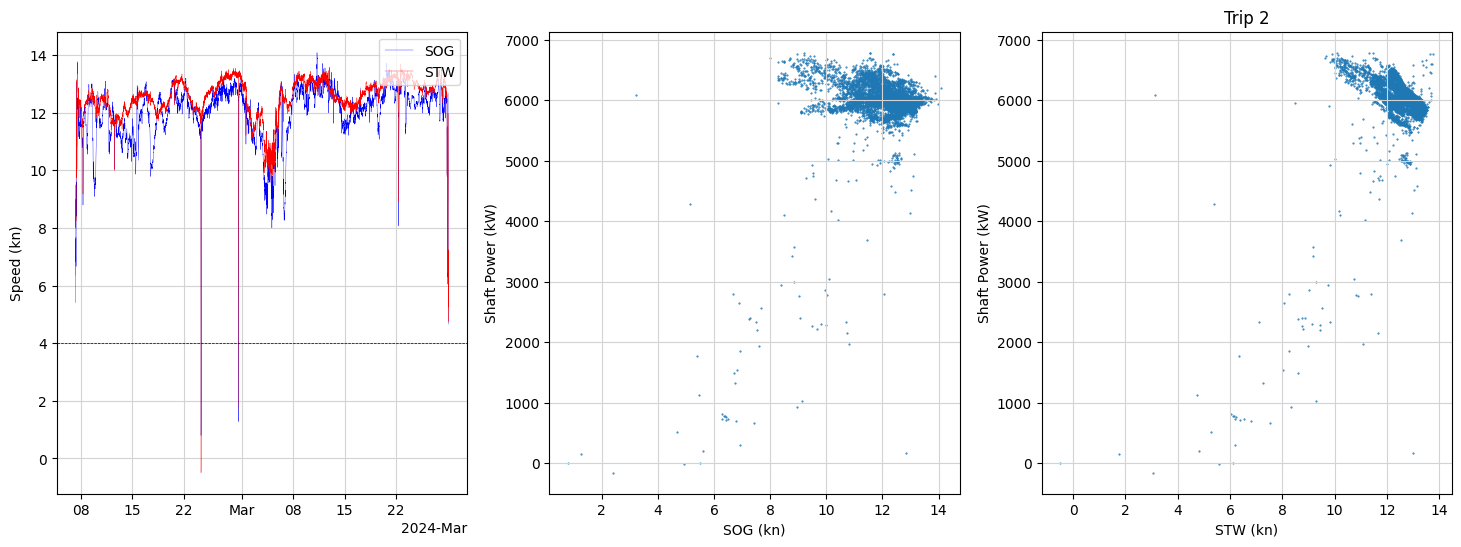

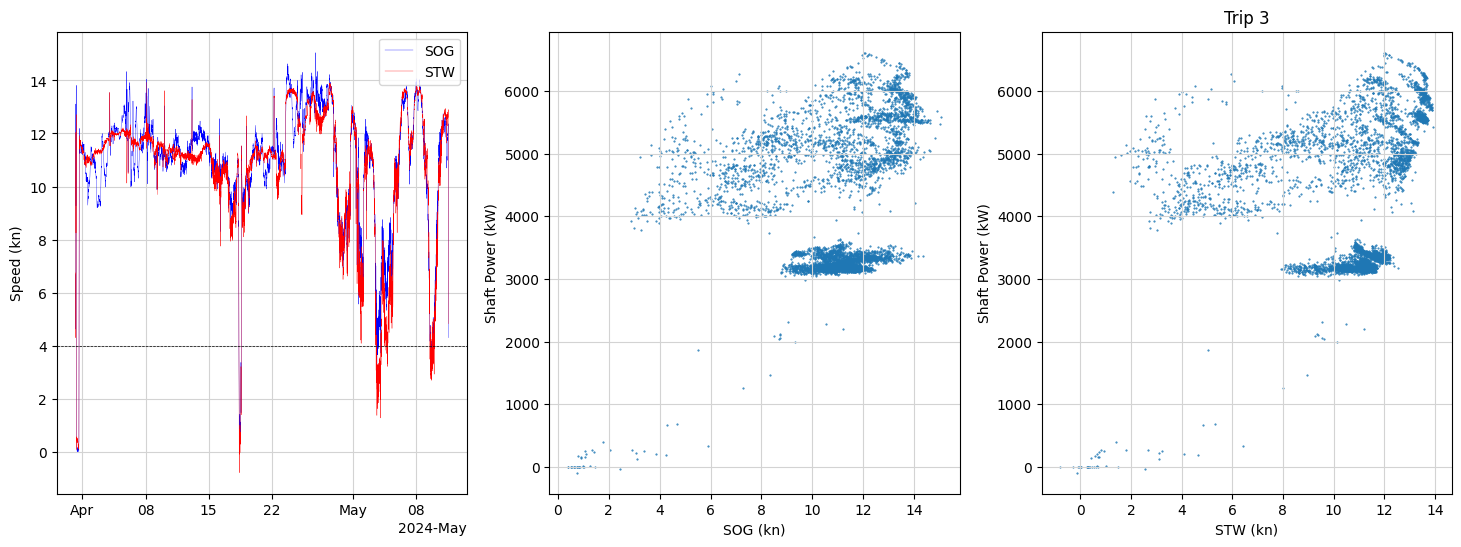

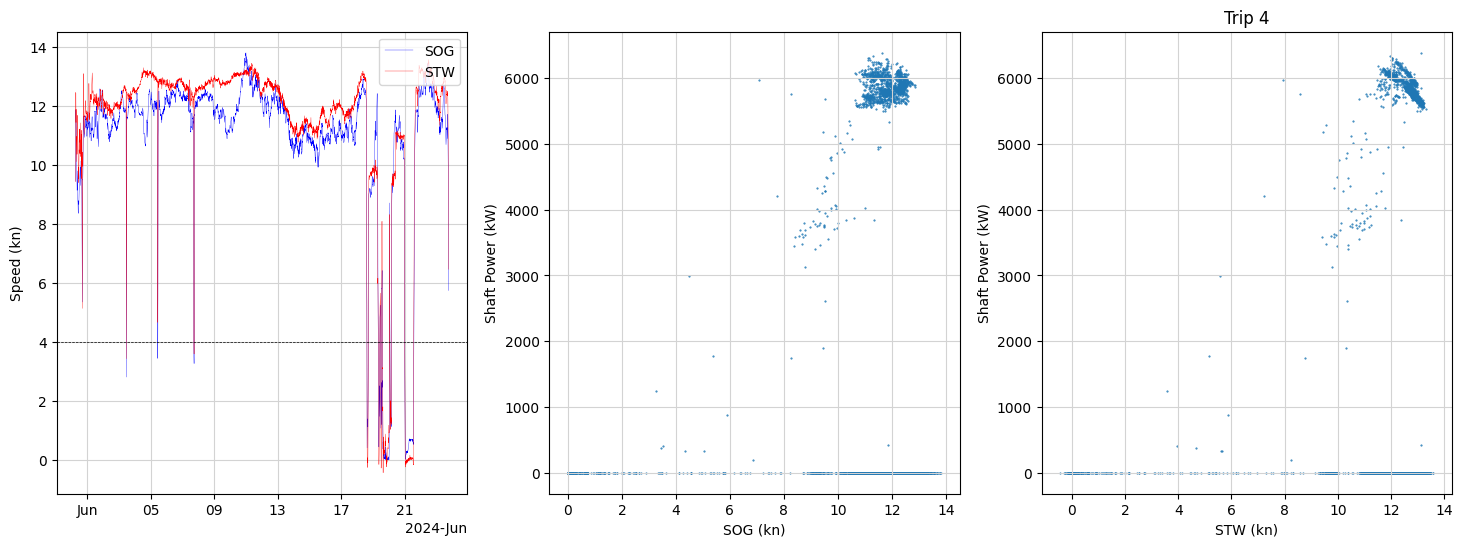

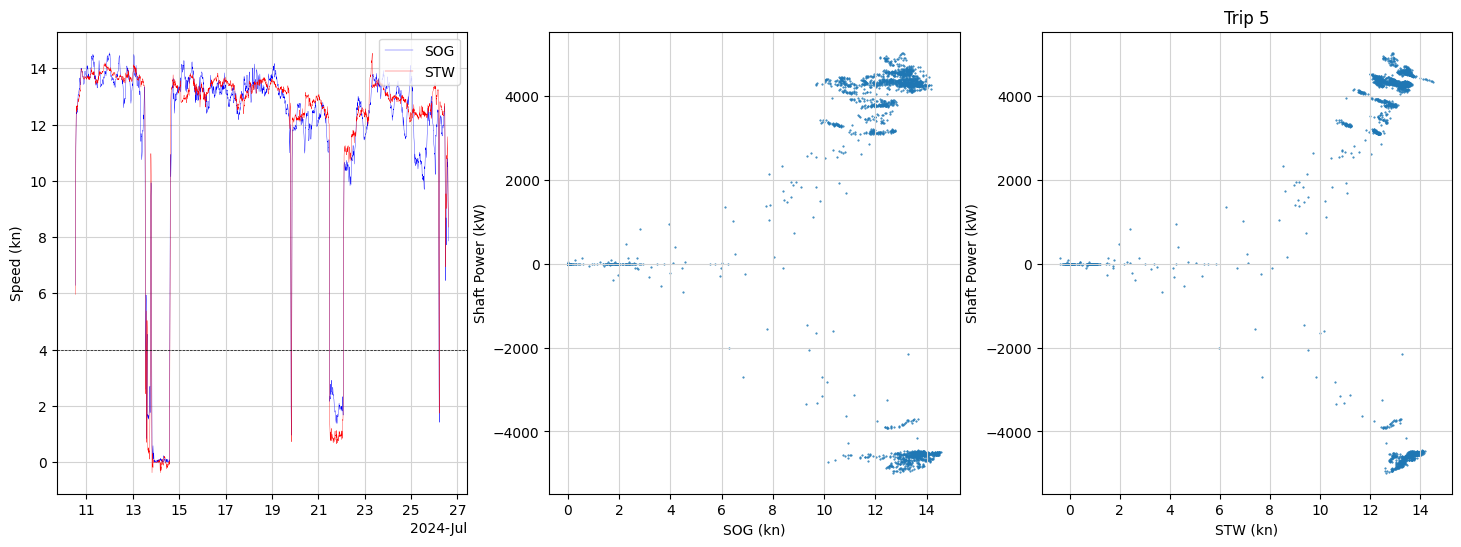

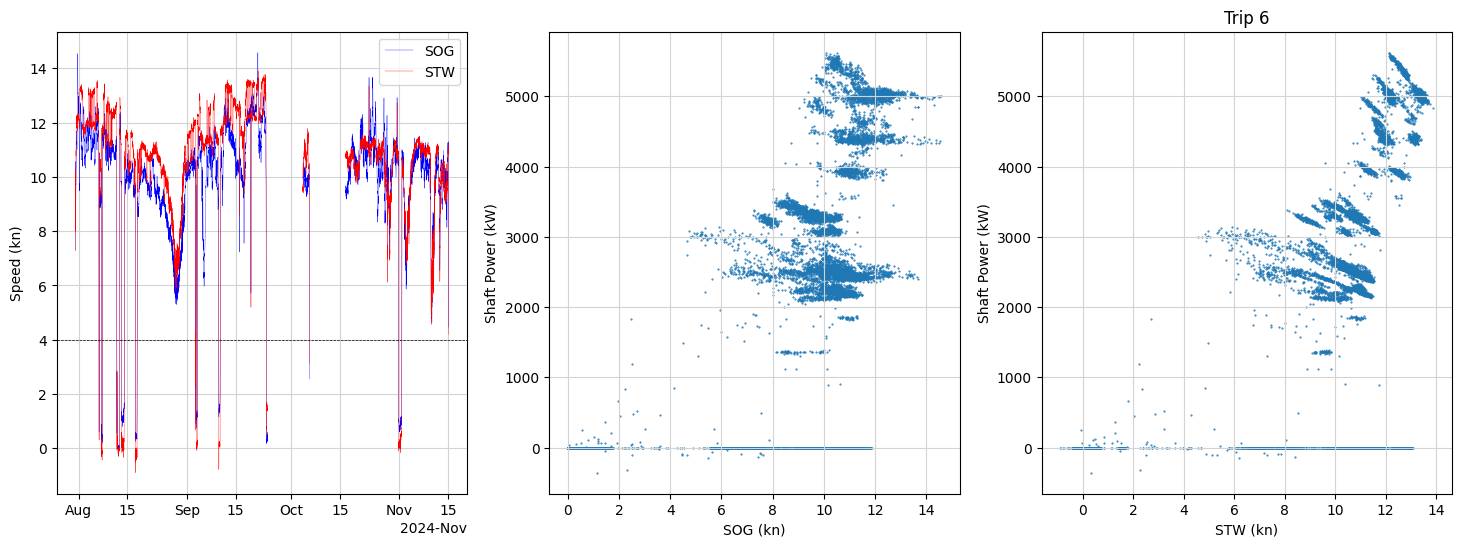

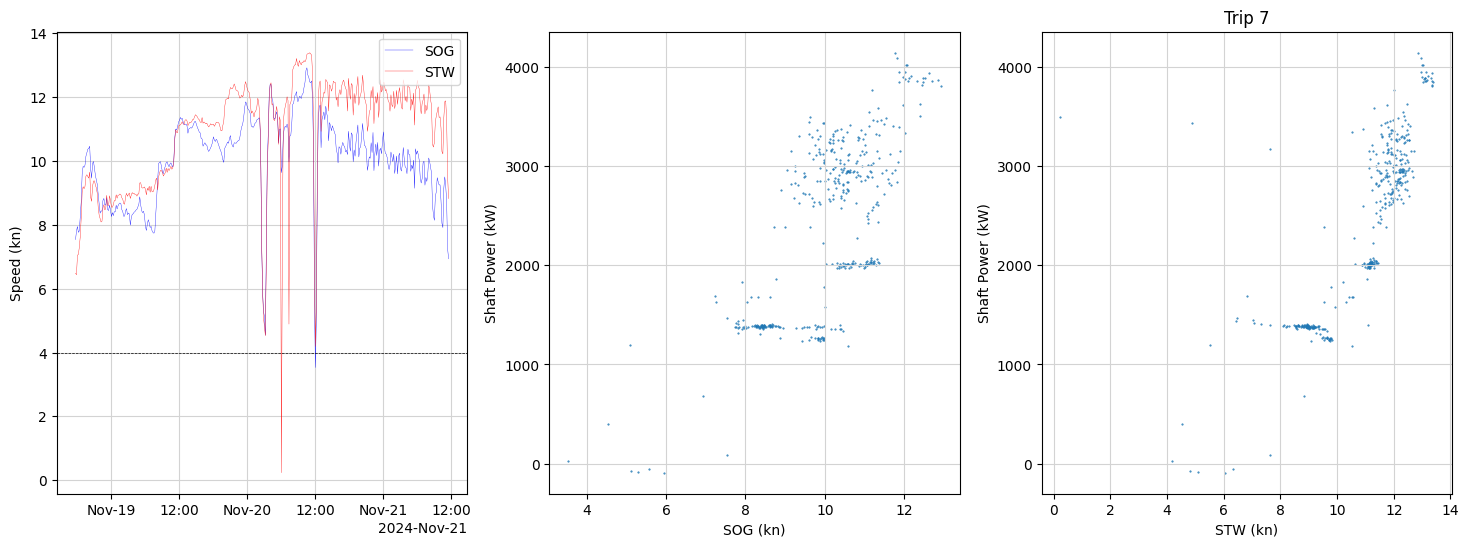

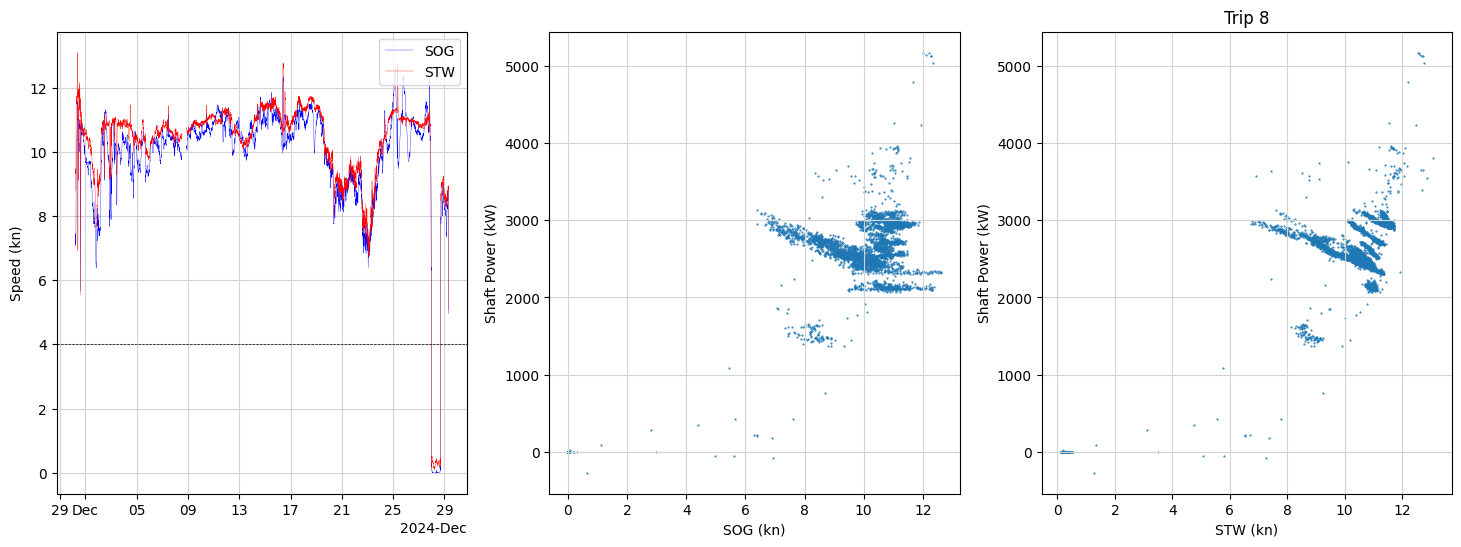

In [11]:
for trip in trips["trip"].unique():
    trip_data = metrics_wide.filter(pl.col("timestamp").is_between(trips.filter(pl.col("trip") == trip).select("start").item(), trips.filter(pl.col("trip") == trip).select("end").item()))
    trip_data = trip_data.select(pl.col("timestamp"),pl.col("stw_kn"),pl.col("sog_kn"), pl.col("shaft_kw")).sort("timestamp").group_by_dynamic("timestamp", every="10m").agg(pl.col("stw_kn").mean(),pl.col("sog_kn").mean(), pl.col("shaft_kw").mean())
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    ax[0].plot(trip_data["timestamp"].to_numpy(), trip_data["sog_kn"].to_numpy(), color = "blue", label = "SOG", lw=0.25)
    ax[0].plot(trip_data["timestamp"].to_numpy(), trip_data["stw_kn"].to_numpy(), color = "red", label = "STW", lw=0.25)
    ax[0].axhline(4, color = "black", ls = "--", lw = 0.5, )
    ax[0].legend(loc= "upper right")
    ax[0].set_ylabel("Speed (kn)")
    loc = mdates.AutoDateLocator()
    ax[0].xaxis.set_major_locator(loc)
    ax[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    

    ax[1].scatter(trip_data["sog_kn"].to_numpy(), trip_data["shaft_kw"].to_numpy(), s = 0.25)
    ax[1].set_xlabel("SOG (kn)")
    ax[1].set_ylabel("Shaft Power (kW)")
    plt.title(f"Trip {trip}")

    ax[2].scatter(trip_data["stw_kn"].to_numpy(), trip_data["shaft_kw"].to_numpy(), s = 0.25)
    ax[2].set_xlabel("STW (kn)")
    ax[2].set_ylabel("Shaft Power (kW)")
   
    plt.show()

### Filtering Shaft Power

* ASSUMPTION: minimum power required for steady state operation is 1500kW 
* Machine Learning for Propulsion Power Prediction and Analysis of Fouling Related Performance Deterioration : filtered values less than 7000 while training ML models 
* power required depends on the type of vessel as well 

In [10]:
filtered_metric_data = metrics_wide.filter(pl.col("shaft_kw") > 1500)

In [13]:
trip1_data = filtered_metric_data.filter(pl.col("timestamp").is_between(trips.filter(pl.col("trip") == 1).select("start").item(), trips.filter(pl.col("trip") == 1.0).select("end").item()))
trip1_data = trip1_data.select(pl.col("timestamp"),pl.col("stw_kn"),pl.col("sog_kn"), pl.col("shaft_kw")).drop_nulls().sort("timestamp").group_by_dynamic("timestamp", every="10m").agg(pl.col("stw_kn").mean(),pl.col("sog_kn").mean(), pl.col("shaft_kw").mean())
result1 = fit_power_law(trip1_data)

Points used: 1322
Fit: P = -1.962·V^2 + 215.6·V + 3168
     V^2:       -1.962 ± 1.84
       V:        215.6 ± 36.2
   const:         3168 ± 166
R² = 0.5099,  RMSE = 478.2 kW


Points used: 1451
Fit: P = -8.542·V^2 + 370.3·V + 2284
     V^2:       -8.542 ± 1.26
       V:        370.3 ± 24.6
   const:         2284 ± 110
R² = 0.7642,  RMSE = 338.2 kW
Points used: 1322
Fit: P = -4.71·V^2 + 278·V + 2835
     V^2:        -4.71 ± 1.3
       V:          278 ± 25.6
   const:         2835 ± 118
R² = 0.6963,  RMSE = 338.5 kW
Points used: 4790
Fit: P = -28.61·V^2 + 560.7·V + 3491
     V^2:       -28.61 ± 2.27
       V:        560.7 ± 51.3
   const:         3491 ± 289
R² = 0.1244,  RMSE = 250.3 kW
Points used: 4790
Fit: P = -57.32·V^2 + 1208·V - 39.72
     V^2:       -57.32 ± 2.78
       V:         1208 ± 66.3
   const:       -39.72 ± 395
R² = 0.2351,  RMSE = 233.9 kW
Points used: 2731
Fit: P = 87.63·V^2 - 1672·V + 1.16e+04
     V^2:        87.63 ± 3.1
       V:        -1672 ± 62.4
   const:     1.16e+04 ± 309
R² = 0.2392,  RMSE = 919.9 kW
Points used: 2671
Fit: P = 102.2·V^2 - 1878·V + 1.206e+04
     V^2:        102.2 ± 3.24
       V:        -1878 ± 63.3
   const:    1.

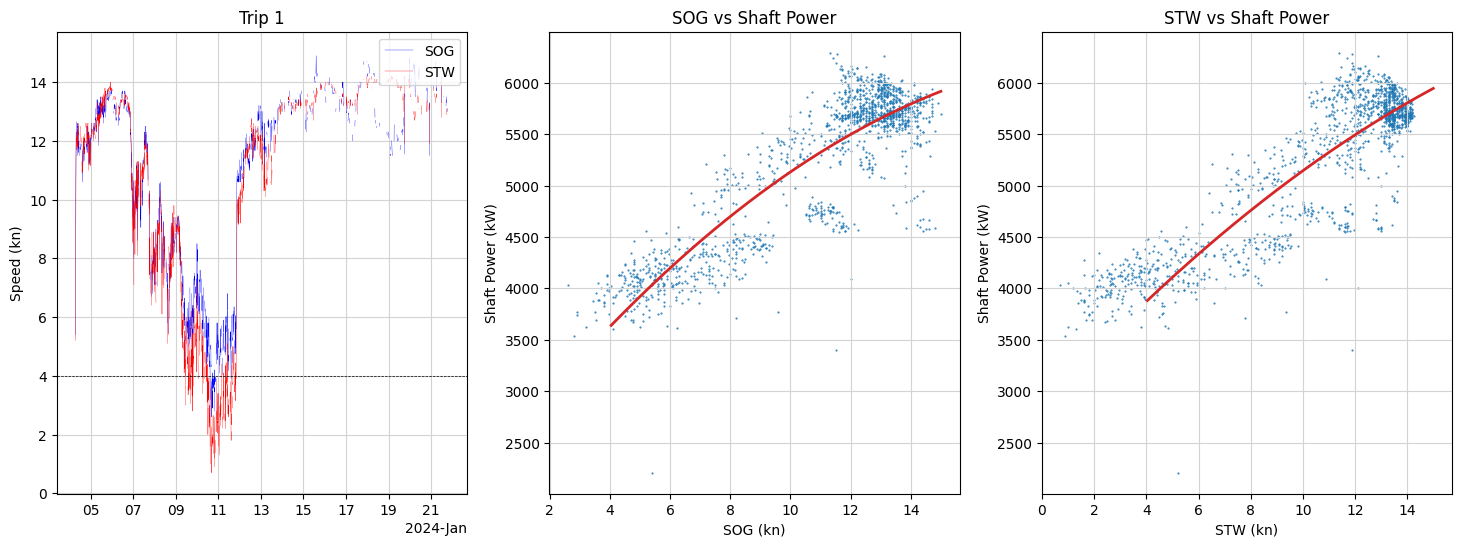

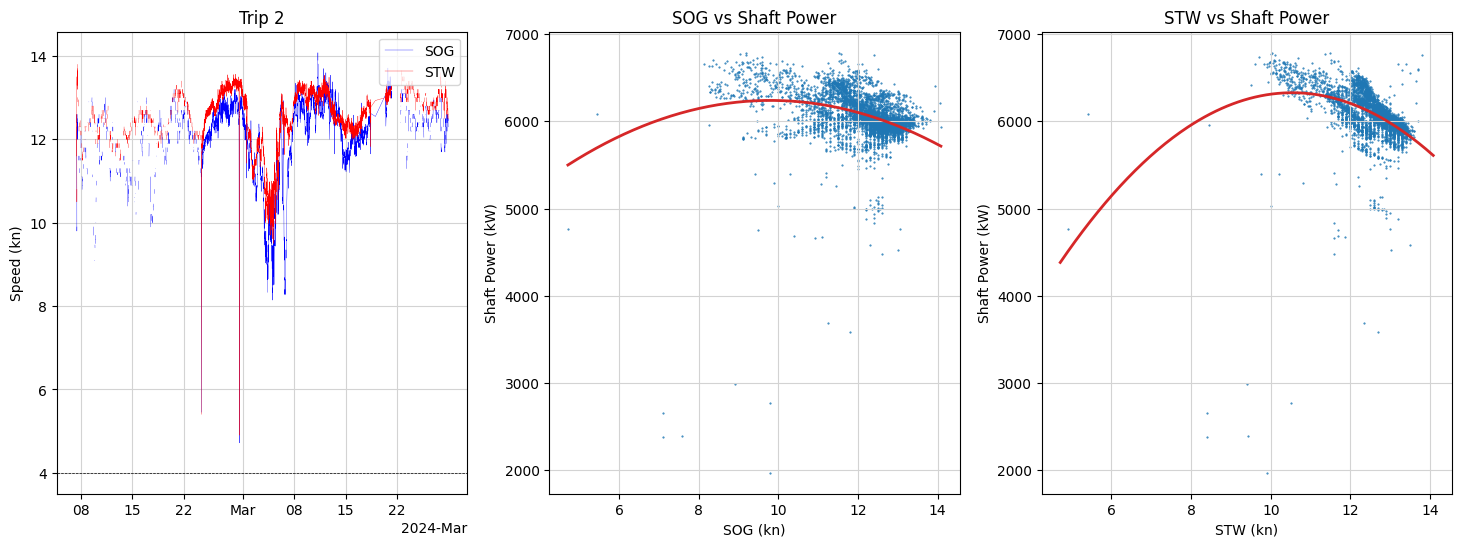

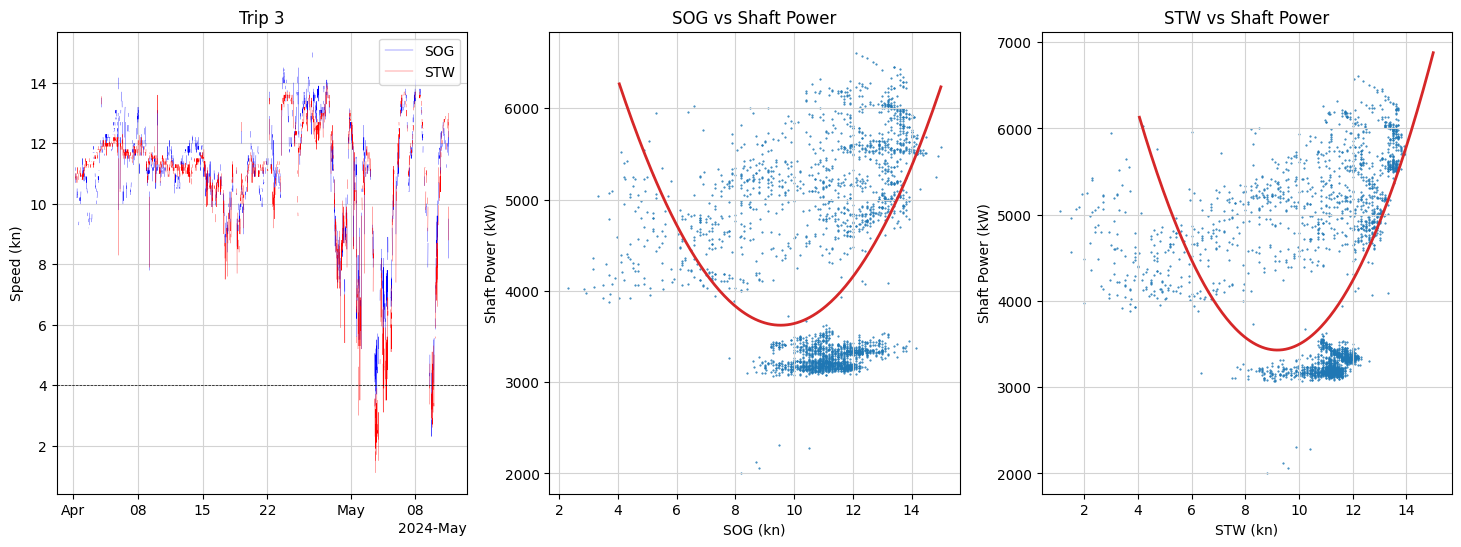

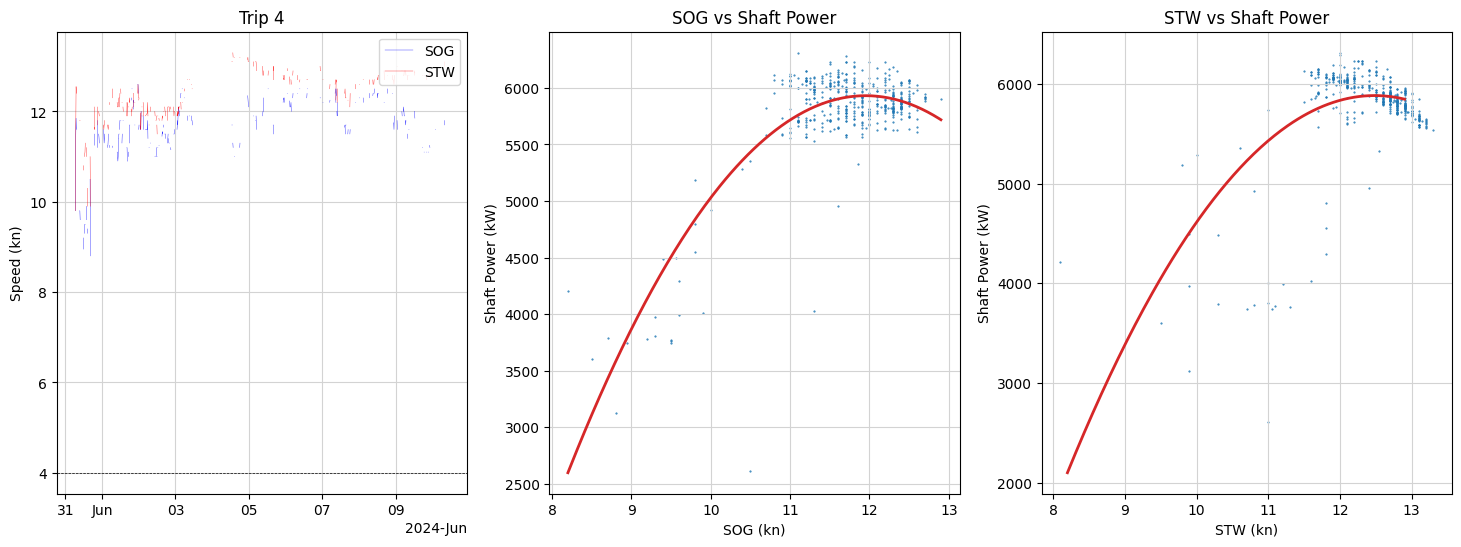

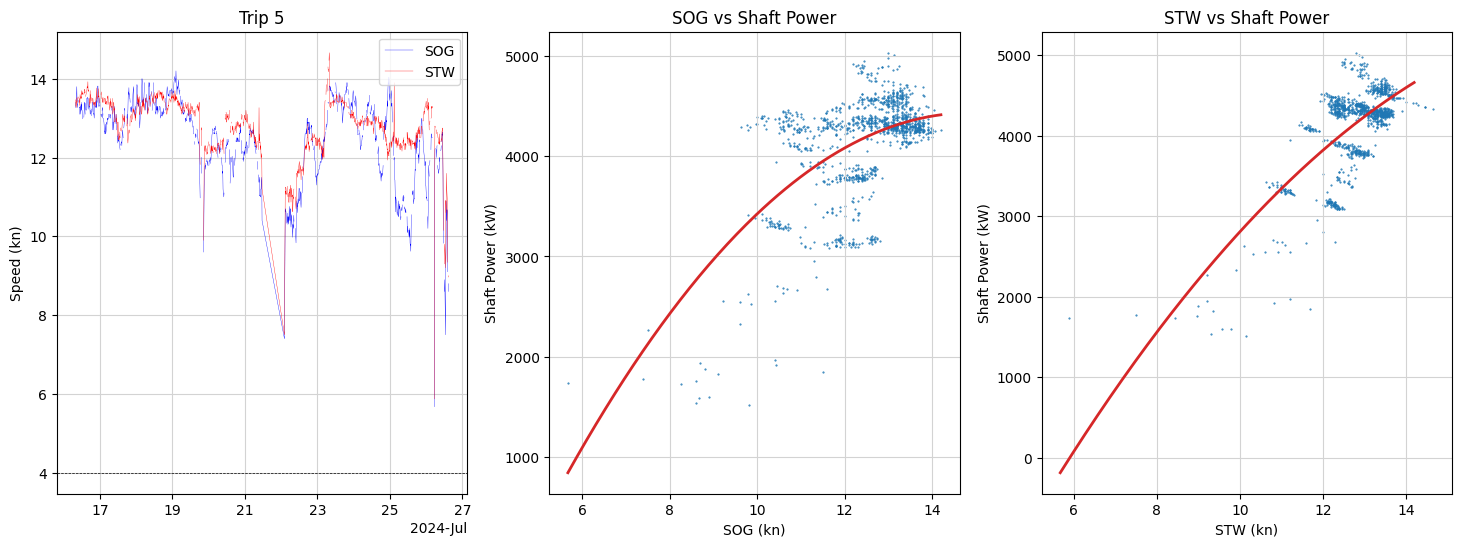

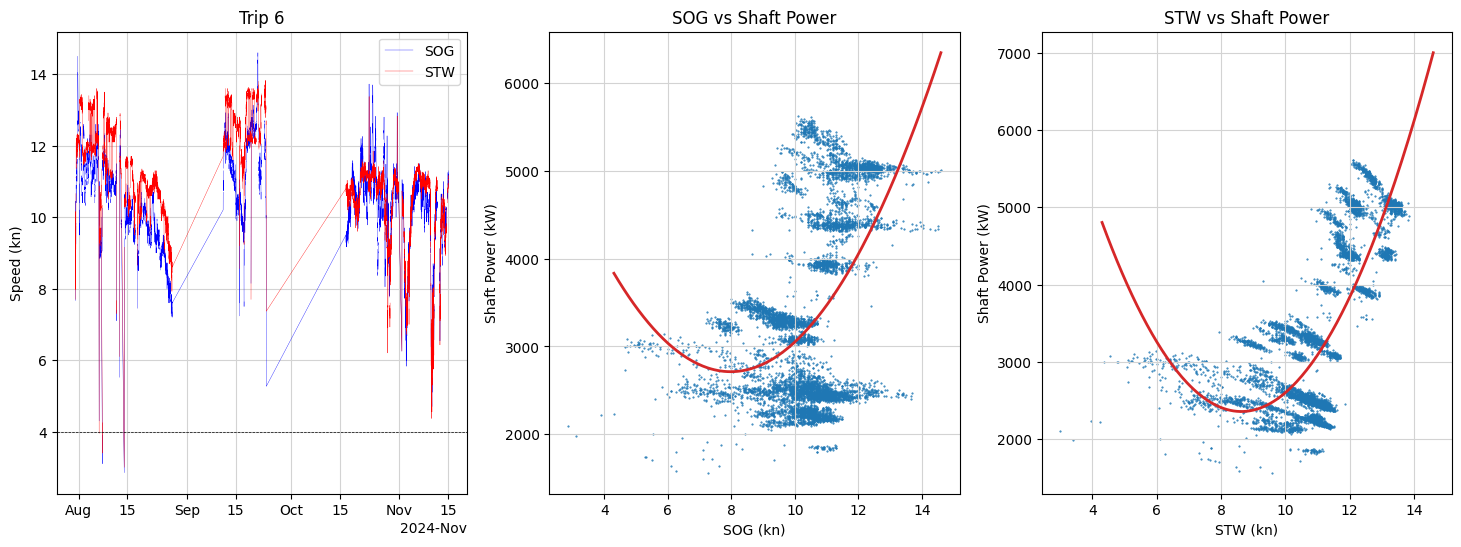

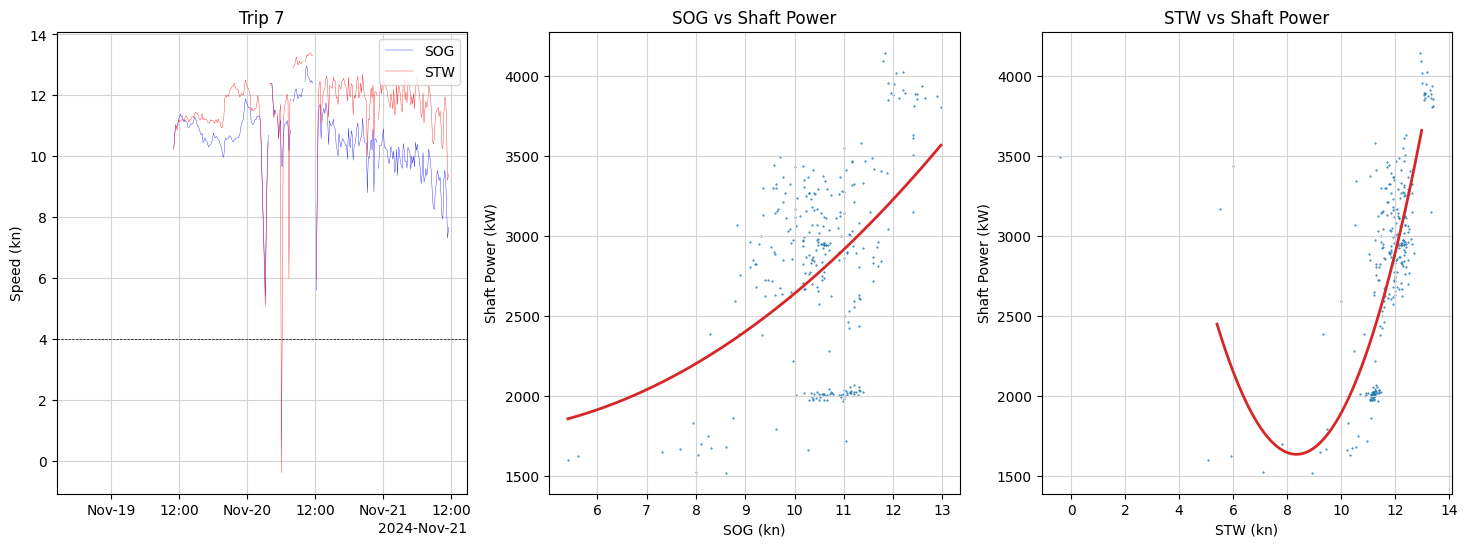

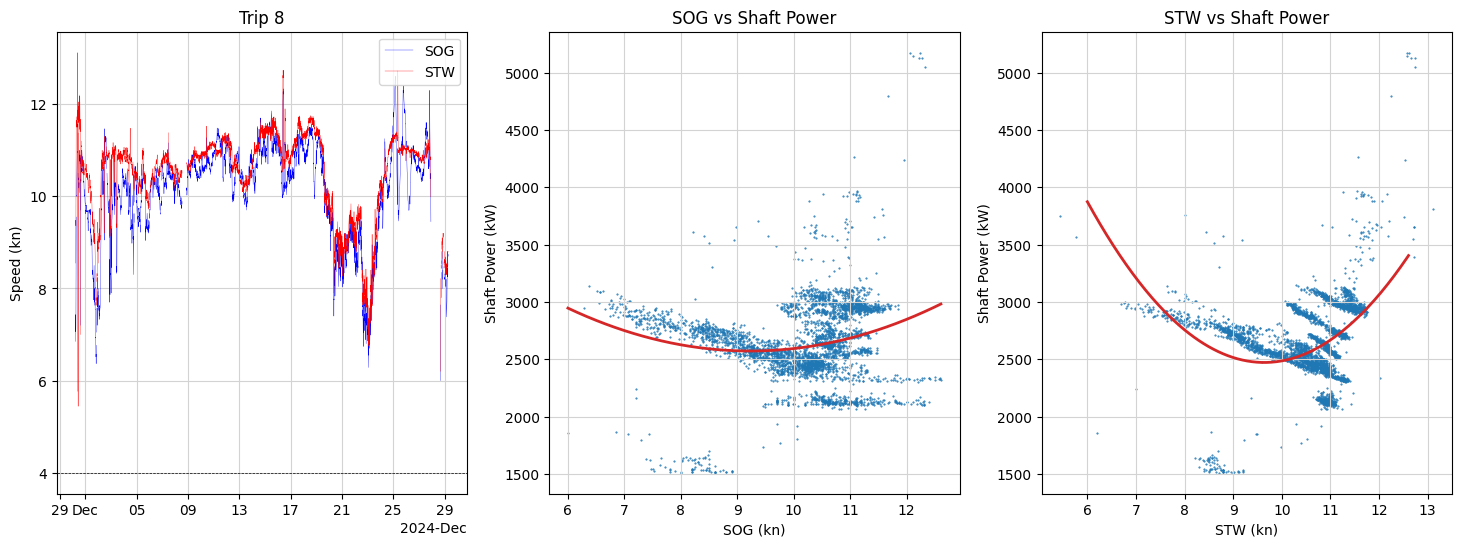

In [12]:
for trip in trips["trip"].unique():
    trip_data = filtered_metric_data.filter(pl.col("timestamp").is_between(trips.filter(pl.col("trip") == trip).select("start").item(), trips.filter(pl.col("trip") == trip).select("end").item()))
    trip_data = trip_data.select(pl.col("timestamp"),pl.col("stw_kn"),pl.col("sog_kn"), pl.col("shaft_kw")).sort("timestamp").group_by_dynamic("timestamp", every="10m").agg(pl.col("stw_kn").mean(),pl.col("sog_kn").mean(), pl.col("shaft_kw").mean())
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    ax[0].plot(trip_data["timestamp"].to_numpy(), trip_data["sog_kn"].to_numpy(), color = "blue", label = "SOG", lw=0.25)
    ax[0].plot(trip_data["timestamp"].to_numpy(), trip_data["stw_kn"].to_numpy(), color = "red", label = "STW", lw=0.25)
    ax[0].axhline(4, color = "black", ls = "--", lw = 0.5, )
    ax[0].legend(loc= "upper right")
    ax[0].set_ylabel("Speed (kn)")
    loc = mdates.AutoDateLocator()
    ax[0].xaxis.set_major_locator(loc)
    ax[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax[0].set_title(f"Trip {trip}")
    
    ax[1].scatter(trip_data["sog_kn"].to_numpy(), trip_data["shaft_kw"].to_numpy(), s = 0.25)
    x, y = _xy(trip_data.select(pl.col("sog_kn"), pl.col("shaft_kw")),SPEED = "sog_kn")
    xs = np.linspace(x.min(), x.max(), 200)
    res = fit_power_law(trip_data.select(pl.col("sog_kn"), pl.col("shaft_kw")),SPEED = "sog_kn")
    ys = poly(xs, *res["coef"])  
    ax[1].plot(xs, ys, color="tab:red", lw=2,)
            #label=f"{name} fit: {_equation(res['coef'])}\nR² = {res['R2']:.3f}, "
            #      f"RMSE = {res['RMSE']:.0f} kW")  
    ax[1].set_xlabel("SOG (kn)")
    ax[1].set_ylabel("Shaft Power (kW)")
    ax[1].set_title("SOG vs Shaft Power")
    
    ax[2].scatter(trip_data["stw_kn"].to_numpy(), trip_data["shaft_kw"].to_numpy(), s = 0.25)
    res = fit_power_law(trip_data.select(pl.col("stw_kn"), pl.col("shaft_kw")),SPEED = "stw_kn")
    ys = poly(xs, *res["coef"])  
    ax[2].plot(xs, ys, color="tab:red", lw=2,)
    ax[2].set_xlabel("STW (kn)")
    ax[2].set_ylabel("Shaft Power (kW)")
    ax[2].set_title("STW vs Shaft Power")
   